
# Project 5: Personal Finance & Budget Analysis Tool
## IDA / 3MTT Data Analysis Bootcamp — Capstone Project
## Part A — Python (Data Cleaning & EDA)
## Dataset: personal_finance.csv (75,000 rows)

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')
 
# Plot styling
sns.set_theme(style='whitegrid', palette='Set2')
plt.rcParams.update({'figure.dpi': 120, 'font.family': 'sans-serif'})
 

In [4]:
df = df[df['year'] != 2024]
print("Records after removing 2024:", len(df))

Records after removing 2024: 74922


In [3]:
# TASK 1: Load and Inspect Data — Check for Anomalies
print("=" * 60)
print("TASK 1: LOAD AND INSPECT DATA")
print("=" * 60)
 
df = pd.read_csv('personal_finance.csv')
 
print("DATASET SHAPE:", df.shape)
print()
print("COLUMN DATA TYPES:")
print(df.dtypes)
print()
print("MISSING VALUES:")
print(df.isnull().sum())
print()
print("AMOUNT STATISTICS (anomaly check):")
print(df['amount_ngn'].describe().apply(lambda x: f'{x:,.2f}'))
print()
print("TRANSACTION TYPE COUNTS:")
print(df['transaction_type'].value_counts())
 

TASK 1: LOAD AND INSPECT DATA
DATASET SHAPE: (75000, 14)

COLUMN DATA TYPES:
transaction_id          str
user_id                 str
transaction_date        str
month                   str
year                  int64
transaction_type        str
category                str
amount_ngn          float64
description             str
payment_method          str
bank                    str
savings_goal_met        str
budget_category         str
notes                   str
dtype: object

MISSING VALUES:
transaction_id          0
user_id                 0
transaction_date        0
month                   0
year                    0
transaction_type        0
category                0
amount_ngn              0
description             0
payment_method          0
bank                    0
savings_goal_met    24994
budget_category         0
notes               21618
dtype: int64

AMOUNT STATISTICS (anomaly check):
count       75,000.00
mean       107,614.11
std        180,324.43
min            200.00

In [5]:
# TASK 2: Separate Income & Expense — Net Savings Per User Per Month
print()
print("TASK 2: INCOME/EXPENSE SPLIT & NET SAVINGS")
 
# Convert date and extract time features
df['transaction_date'] = pd.to_datetime(df['transaction_date'])
df['year_month'] = df['transaction_date'].dt.to_period('M')
 
# Handle nulls
df['savings_goal_met'] = df['savings_goal_met'].fillna('N/A')
df['notes'] = df['notes'].fillna('Not Specified')
 
# Separate income and expense
income_df = df[df['transaction_type'] == 'Income'].copy()
expense_df = df[df['transaction_type'] == 'Expense'].copy()
 
print(f"Total Records:   {len(df):,}")
print(f"Income Records:  {len(income_df):,}  ({len(income_df)/len(df)*100:.1f}%)")
print(f"Expense Records: {len(expense_df):,}  ({len(expense_df)/len(df)*100:.1f}%)")
 
# Net savings per user per month
income_monthly = (
    income_df.groupby(['user_id', 'year_month'])['amount_ngn']
    .sum().reset_index().rename(columns={'amount_ngn': 'total_income'})
)
expense_monthly = (
    expense_df.groupby(['user_id', 'year_month'])['amount_ngn']
    .sum().reset_index().rename(columns={'amount_ngn': 'total_expense'})
)
net_savings = pd.merge(income_monthly, expense_monthly,
                       on=['user_id', 'year_month'], how='outer').fillna(0)
net_savings['net_savings'] = net_savings['total_income'] - net_savings['total_expense']
net_savings['savings_rate'] = np.where(
    net_savings['total_income'] > 0,
    (net_savings['net_savings'] / net_savings['total_income']) * 100, 0
)
 
print()
print("NET SAVINGS SAMPLE (first 5 rows):")
print(net_savings.head().to_string(index=False))
print(f"\nUsers with positive net savings: {(net_savings['net_savings'] > 0).sum():,}")
print(f"Users with negative net savings: {(net_savings['net_savings'] < 0).sum():,}")
 


TASK 2: INCOME/EXPENSE SPLIT & NET SAVINGS
Total Records:   74,922
Income Records:  11,436  (15.3%)
Expense Records: 63,486  (84.7%)

NET SAVINGS SAMPLE (first 5 rows):
   user_id year_month  total_income  total_expense  net_savings  savings_rate
USR-500000    2021-01           0.0         1900.0      -1900.0           0.0
USR-500000    2021-03           0.0        90100.0     -90100.0           0.0
USR-500000    2021-05           0.0        20190.0     -20190.0           0.0
USR-500000    2021-07           0.0         2370.0      -2370.0           0.0
USR-500000    2021-08           0.0        35460.0     -35460.0           0.0

Users with positive net savings: 11,066
Users with negative net savings: 50,337



TASK 3: CHART — TOTAL SPENDING BY CATEGORY


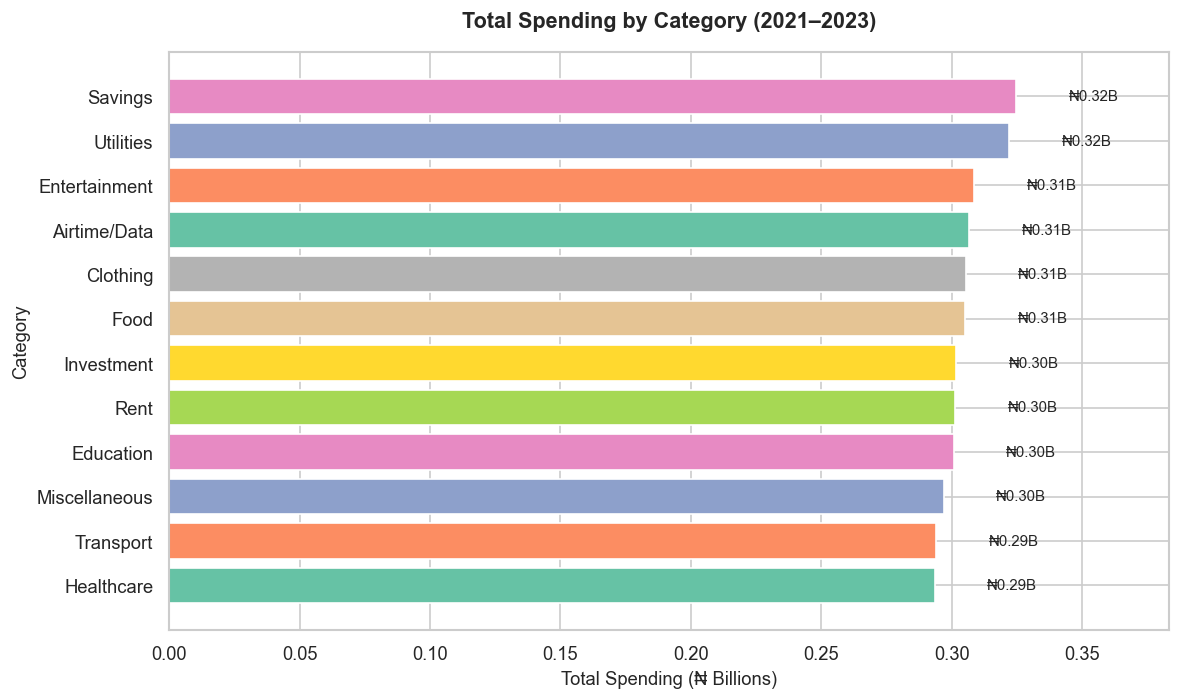

Top 3 spending categories:
     category  amount_billions
      Savings         0.324709
    Utilities         0.322046
Entertainment         0.308653


In [6]:
# TASK 3: Bar Chart — Total Spending by Category
print()
print("TASK 3: CHART — TOTAL SPENDING BY CATEGORY")
 
total_by_cat = (
    expense_df.groupby('category')['amount_ngn']
    .sum().sort_values(ascending=True).reset_index()
)
total_by_cat['amount_billions'] = total_by_cat['amount_ngn'] / 1e9
 
fig, ax = plt.subplots(figsize=(10, 6))
bars = ax.barh(total_by_cat['category'], total_by_cat['amount_billions'],
               color=sns.color_palette('Set2', len(total_by_cat)))
for bar, val in zip(bars, total_by_cat['amount_billions']):
    ax.text(bar.get_width() + 0.02, bar.get_y() + bar.get_height() / 2,
            f'₦{val:.2f}B', va='center', fontsize=9)
ax.set_xlabel('Total Spending (₦ Billions)', fontsize=11)
ax.set_ylabel('Category', fontsize=11)
ax.set_title('Total Spending by Category (2021–2023)', fontsize=13,
             fontweight='bold', pad=15)
ax.set_xlim(0, total_by_cat['amount_billions'].max() * 1.18)
plt.tight_layout()
plt.savefig('chart1_spending_by_category.png', bbox_inches='tight')
plt.show()
 
print("Top 3 spending categories:")
print(total_by_cat.sort_values('amount_ngn', ascending=False)
      [['category', 'amount_billions']].head(3).to_string(index=False))
 


TASK 4: CHART — MONTHLY INCOME VS EXPENSE TREND


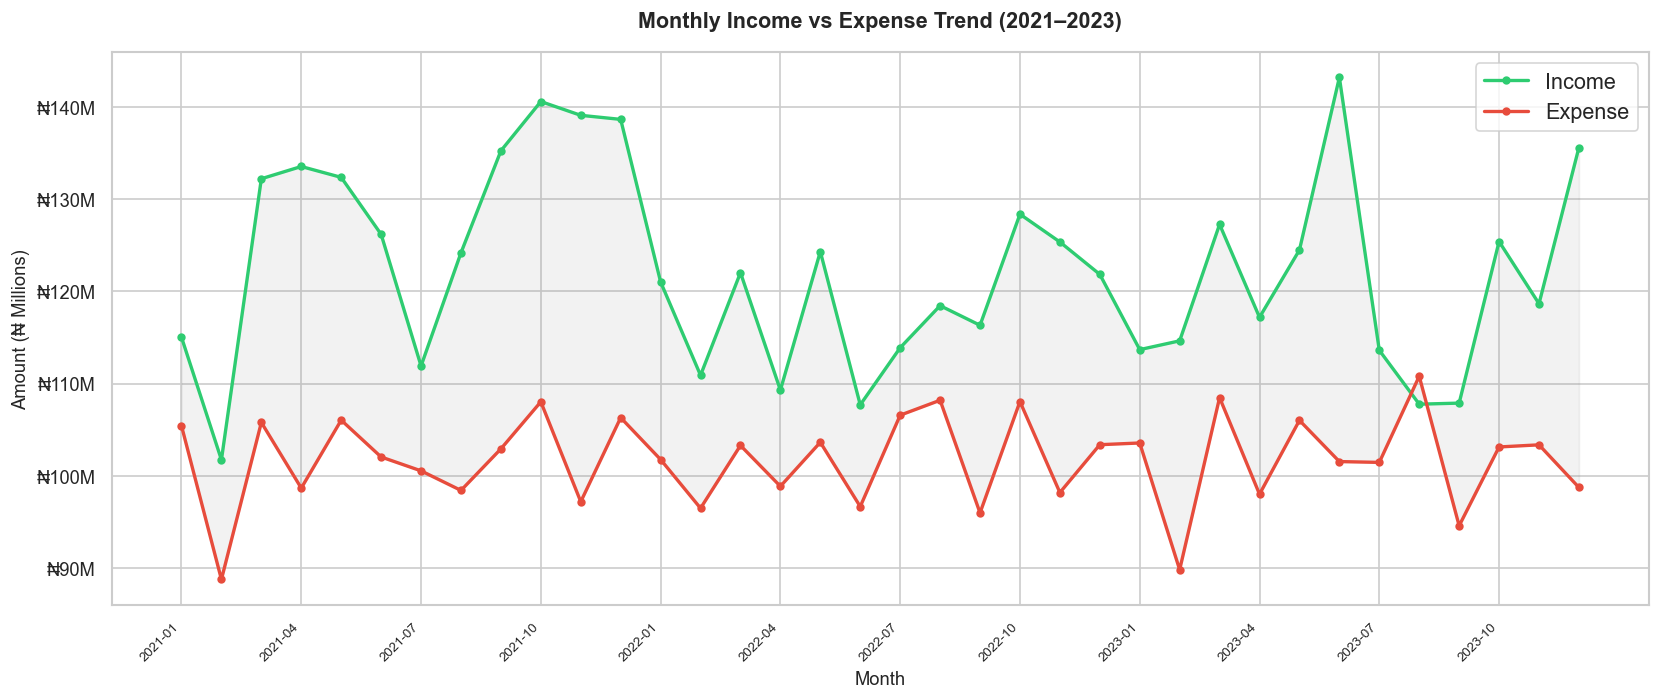

In [7]:
# TASK 4: Line Chart — Monthly Income vs Expense Trend
print()
print("TASK 4: CHART — MONTHLY INCOME VS EXPENSE TREND")
 
monthly_trend = (
    df.groupby(['year_month', 'transaction_type'])['amount_ngn']
    .sum().reset_index()
)
monthly_trend['year_month_str'] = monthly_trend['year_month'].astype(str)
monthly_pivot = monthly_trend.pivot(
    index='year_month_str', columns='transaction_type', values='amount_ngn'
).fillna(0).sort_index()
 
fig, ax = plt.subplots(figsize=(14, 6))
ax.plot(monthly_pivot.index, monthly_pivot['Income'] / 1e6,
        marker='o', markersize=4, linewidth=2, label='Income', color='#2ecc71')
ax.plot(monthly_pivot.index, monthly_pivot['Expense'] / 1e6,
        marker='o', markersize=4, linewidth=2, label='Expense', color='#e74c3c')
ax.fill_between(monthly_pivot.index,
                monthly_pivot['Income'] / 1e6,
                monthly_pivot['Expense'] / 1e6,
                alpha=0.1, color='grey')
tick_positions = range(0, len(monthly_pivot.index), 3)
ax.set_xticks(list(tick_positions))
ax.set_xticklabels([monthly_pivot.index[i] for i in tick_positions],
                   rotation=45, ha='right', fontsize=8)
ax.set_xlabel('Month', fontsize=11)
ax.set_ylabel('Amount (₦ Millions)', fontsize=11)
ax.set_title('Monthly Income vs Expense Trend (2021–2023)',
             fontsize=13, fontweight='bold', pad=15)
ax.legend(fontsize=13)
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'₦{x:.0f}M'))
plt.tight_layout()
plt.savefig('chart2_monthly_income_expense.png', bbox_inches='tight')
plt.show()
 
 


TASK 5: CHART — SPENDING CATEGORY SHARE


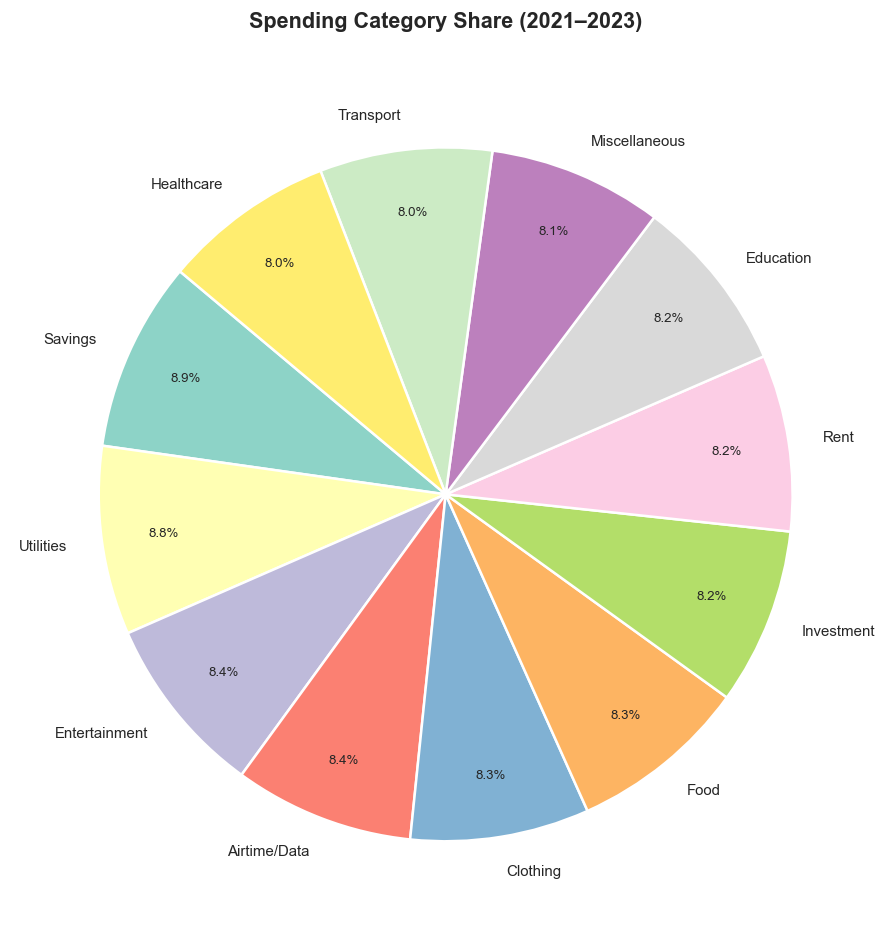

Category Shares:
  Savings              8.9%
  Utilities            8.8%
  Entertainment        8.4%
  Airtime/Data         8.4%
  Clothing             8.3%
  Food                 8.3%
  Investment           8.2%
  Rent                 8.2%
  Education            8.2%
  Miscellaneous        8.1%
  Transport            8.0%
  Healthcare           8.0%


In [8]:
# TASK 5: Pie Chart — Spending Category Share
print()
print("TASK 5: CHART — SPENDING CATEGORY SHARE")
 
cat_share = expense_df.groupby('category')['amount_ngn'].sum().sort_values(ascending=False)
colors = sns.color_palette('Set3', len(cat_share))
 
fig, ax = plt.subplots(figsize=(10, 8))
wedges, texts, autotexts = ax.pie(
    cat_share.values,
    labels=cat_share.index,
    autopct=lambda p: f'{p:.1f}%' if p > 3 else '',
    colors=colors,
    startangle=140,
    pctdistance=0.82,
    wedgeprops={'edgecolor': 'white', 'linewidth': 1.5}
)
for text in texts:
    text.set_fontsize(9)
for autotext in autotexts:
    autotext.set_fontsize(8)
ax.set_title('Spending Category Share (2021–2023)', fontsize=13,
             fontweight='bold', pad=20)
plt.tight_layout()
plt.savefig('chart3_spending_category_share.png', bbox_inches='tight')
plt.show()
 
print("Category Shares:")
for cat, val in (cat_share / cat_share.sum() * 100).items():
    print(f"  {cat:<20} {val:.1f}%")
 


TASK 6: CHART — EXPENSE DISTRIBUTION BY CATEGORY


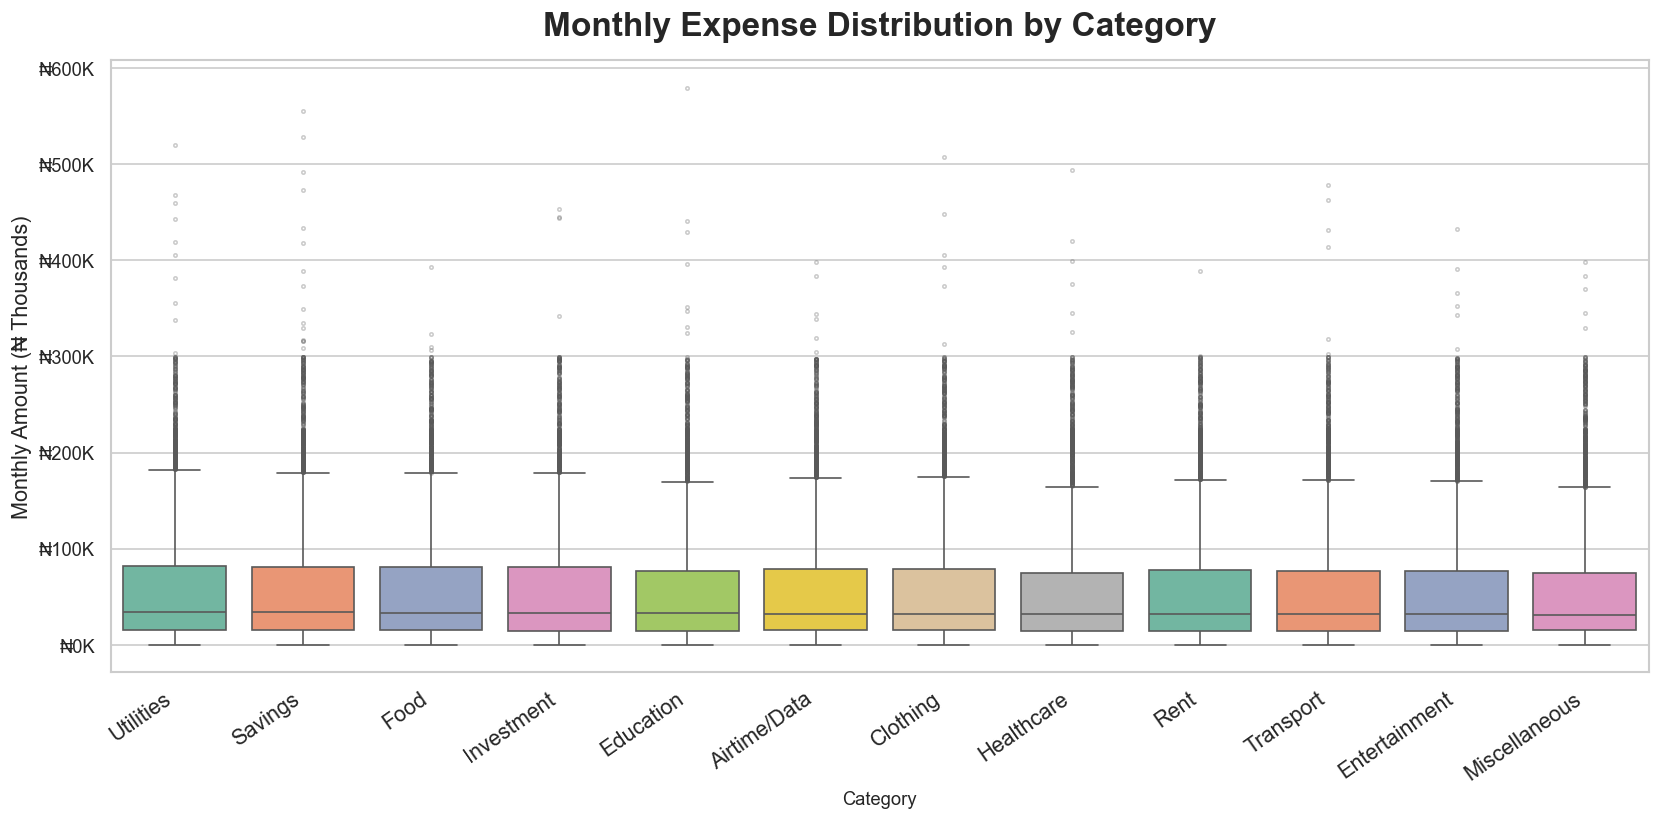

In [9]:
# TASK 6: Box Plot — Monthly Expense Distribution by Category
print()
print("TASK 6: CHART — EXPENSE DISTRIBUTION BY CATEGORY")
 
monthly_cat = (
    expense_df.groupby(['user_id', 'year_month', 'category'])['amount_ngn']
    .sum().reset_index()
)
monthly_cat['amount_k'] = monthly_cat['amount_ngn'] / 1000
cat_order = (monthly_cat.groupby('category')['amount_k']
             .median().sort_values(ascending=False).index)
 
fig, ax = plt.subplots(figsize=(14, 7))
sns.boxplot(
    data=monthly_cat, x='category', y='amount_k',
    order=cat_order, palette='Set2',
    flierprops={'marker': 'o', 'markersize': 2, 'alpha': 0.3}, ax=ax
)
ax.set_xlabel('Category', fontsize=11)
ax.set_ylabel('Monthly Amount (₦ Thousands)', fontsize=13)
ax.set_title('Monthly Expense Distribution by Category',
             fontsize=20, fontweight='bold', pad=15)
ax.set_xticklabels(ax.get_xticklabels(), rotation=35, ha='right', fontsize=13)
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'₦{x:.0f}K'))
plt.tight_layout()
plt.savefig('chart4_boxplot_expense_by_category.png', bbox_inches='tight')
plt.show()
 


TASK 7: CHART — SAVINGS BY INCOME BRACKET


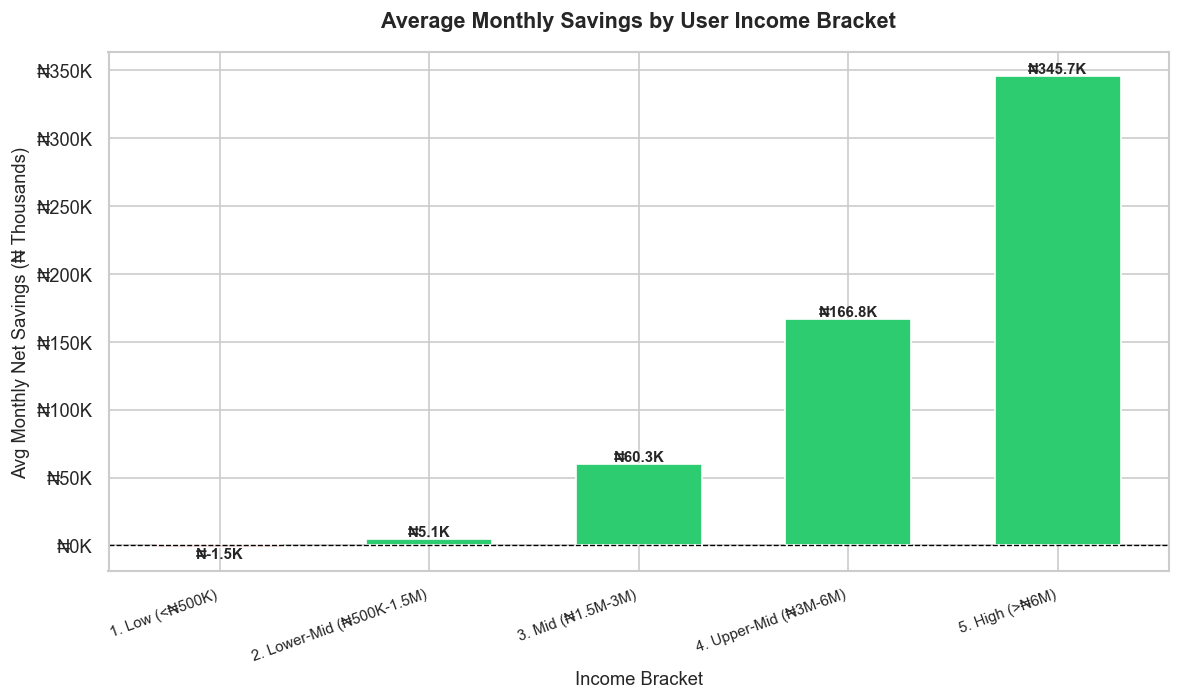

In [10]:
# TASK 7: Bar Chart — Average Monthly Savings by Income Bracket
print()
print("TASK 7: CHART — SAVINGS BY INCOME BRACKET")
 
user_income = income_df.groupby('user_id')['amount_ngn'].sum().reset_index()
user_income.columns = ['user_id', 'total_income']
 
def income_bracket(income):
    if income < 500_000:
        return '1. Low (<₦500K)'
    elif income < 1_500_000:
        return '2. Lower-Mid (₦500K-1.5M)'
    elif income < 3_000_000:
        return '3. Mid (₦1.5M-3M)'
    elif income < 6_000_000:
        return '4. Upper-Mid (₦3M-6M)'
    else:
        return '5. High (>₦6M)'
 
user_income['income_bracket'] = user_income['total_income'].apply(income_bracket)
user_net = net_savings.groupby('user_id')['net_savings'].mean().reset_index()
user_net.columns = ['user_id', 'avg_monthly_savings']
bracket_savings = user_net.merge(
    user_income[['user_id', 'income_bracket']], on='user_id', how='left'
)
bracket_avg = bracket_savings.groupby('income_bracket')['avg_monthly_savings'].mean().reset_index()
bracket_avg['avg_savings_k'] = bracket_avg['avg_monthly_savings'] / 1000
 
fig, ax = plt.subplots(figsize=(10, 6))
colors = ['#e74c3c' if v < 0 else '#2ecc71' for v in bracket_avg['avg_savings_k']]
bars = ax.bar(bracket_avg['income_bracket'], bracket_avg['avg_savings_k'],
              color=colors, edgecolor='white', width=0.6)
for bar, val in zip(bars, bracket_avg['avg_savings_k']):
    ax.text(bar.get_x() + bar.get_width() / 2,
            bar.get_height() + (2 if val >= 0 else -8),
            f'₦{val:.1f}K', ha='center', fontsize=9, fontweight='bold')
ax.axhline(0, color='black', linewidth=0.8, linestyle='--')
ax.set_xlabel('Income Bracket', fontsize=11)
ax.set_ylabel('Avg Monthly Net Savings (₦ Thousands)', fontsize=11)
ax.set_title('Average Monthly Savings by User Income Bracket',
             fontsize=13, fontweight='bold', pad=15)
ax.set_xticklabels(bracket_avg['income_bracket'], rotation=20, ha='right', fontsize=9)
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'₦{x:.0f}K'))
plt.tight_layout()
plt.savefig('chart5_savings_by_income_bracket.png', bbox_inches='tight')
plt.show()
 


TASK 8: CHART — TOP BANKS BY TRANSACTION VOLUME


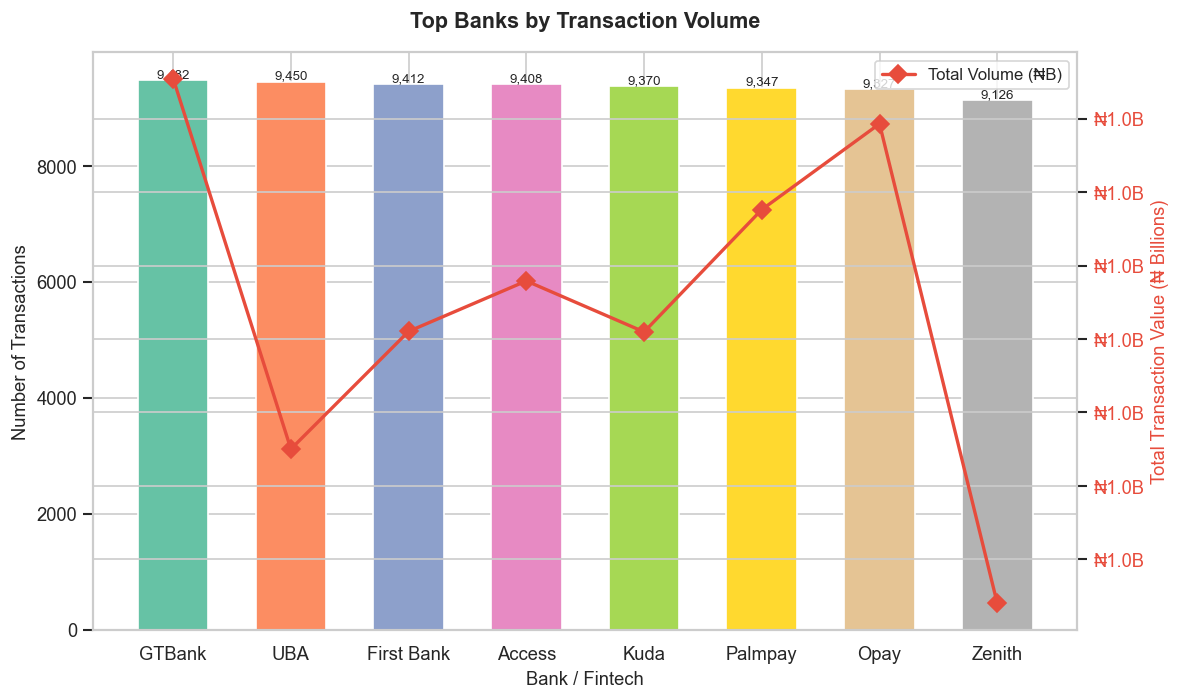

Bank Summary:
      bank  transaction_count  volume_billions
    GTBank               9482         1.022725
       UBA               9450         0.997505
First Bank               9412         1.005515
    Access               9408         1.008949
      Kuda               9370         1.005480
   Palmpay               9347         1.013806
      Opay               9327         1.019647
    Zenith               9126         0.987007


In [11]:
# TASK 8: Bar Chart — Top Banks by Transaction Volume
print()
print("TASK 8: CHART — TOP BANKS BY TRANSACTION VOLUME")
 
bank_vol = df.groupby('bank').agg(
    transaction_count=('transaction_id', 'count'),
    total_volume=('amount_ngn', 'sum')
).reset_index().sort_values('transaction_count', ascending=False)
bank_vol['volume_billions'] = bank_vol['total_volume'] / 1e9
 
fig, ax1 = plt.subplots(figsize=(10, 6))
colors = sns.color_palette('Set2', len(bank_vol))
bars = ax1.bar(bank_vol['bank'], bank_vol['transaction_count'],
               color=colors, edgecolor='white', width=0.6)
ax1.set_xlabel('Bank / Fintech', fontsize=11)
ax1.set_ylabel('Number of Transactions', fontsize=11)
ax1.set_title('Top Banks by Transaction Volume', fontsize=13,
              fontweight='bold', pad=15)
ax2 = ax1.twinx()
ax2.plot(bank_vol['bank'], bank_vol['volume_billions'],
         color='#e74c3c', marker='D', linewidth=2, markersize=8,
         label='Total Volume (₦B)')
ax2.set_ylabel('Total Transaction Value (₦ Billions)', fontsize=11, color='#e74c3c')
ax2.tick_params(axis='y', labelcolor='#e74c3c')
ax2.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'₦{x:.1f}B'))
ax2.legend(loc='upper right', fontsize=10)
for bar, count in zip(bars, bank_vol['transaction_count']):
    ax1.text(bar.get_x() + bar.get_width() / 2,
             bar.get_height() + 50, f'{count:,}', ha='center', fontsize=8)
plt.tight_layout()
plt.savefig('chart6_banks_by_volume.png', bbox_inches='tight')
plt.show()
 
print("Bank Summary:")
print(bank_vol[['bank', 'transaction_count', 'volume_billions']].to_string(index=False))
 


TASK 9: CHART — SPENDING HEATMAP BY CATEGORY & MONTH


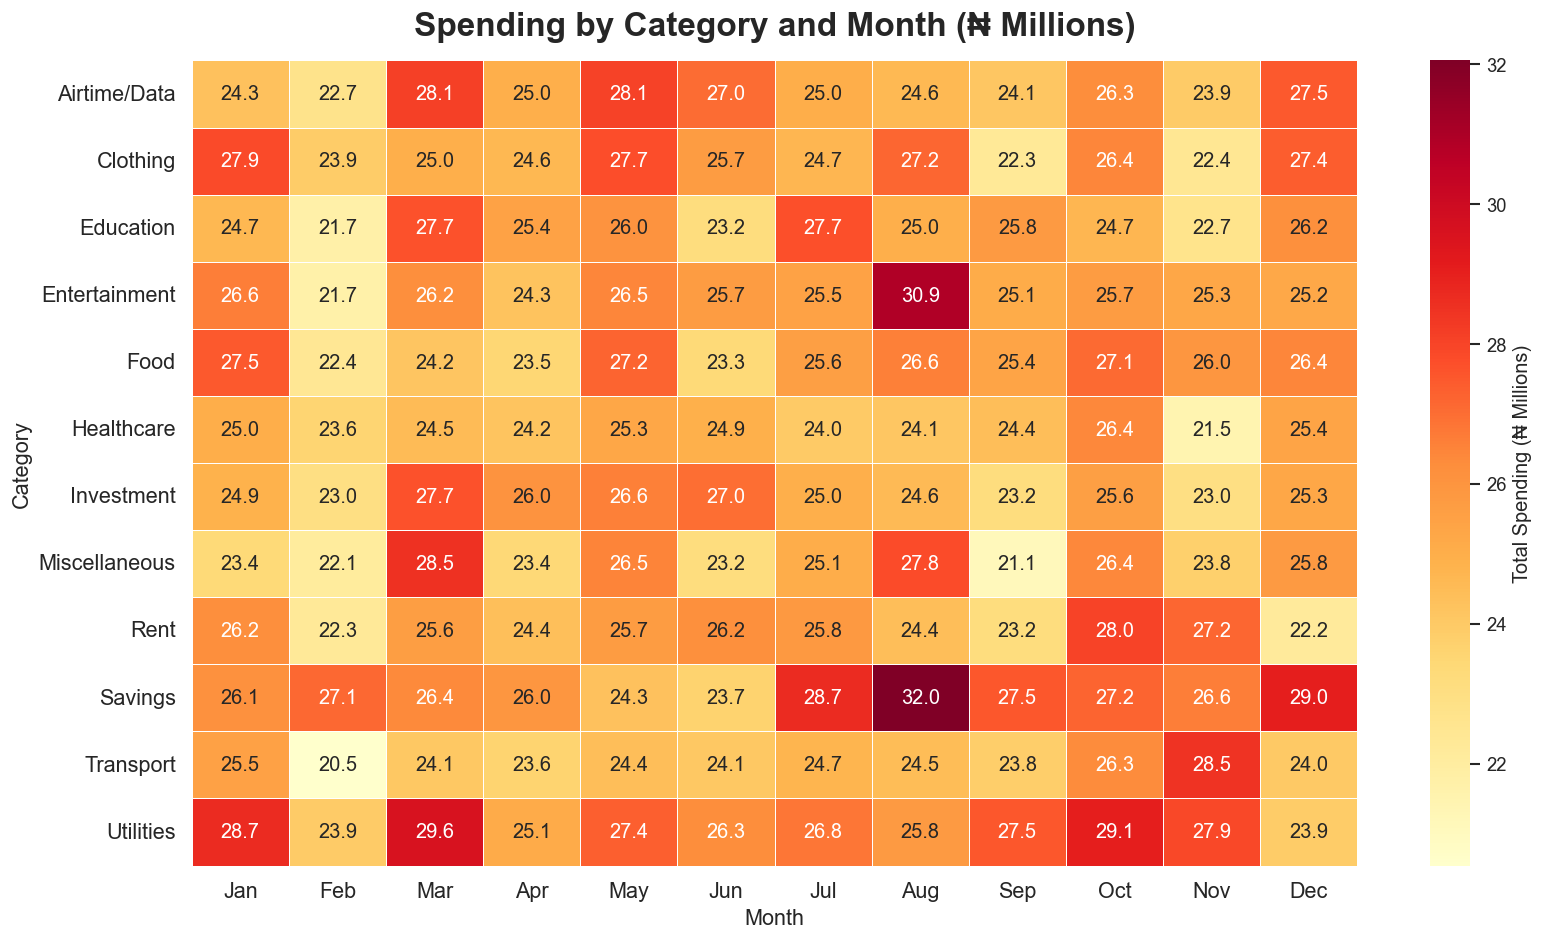

In [12]:
# TASK 9: Heatmap — Spending by Category and Month
print()
print("TASK 9: CHART — SPENDING HEATMAP BY CATEGORY & MONTH")
 
expense_df2 = expense_df.copy()
expense_df2['month_name'] = expense_df2['transaction_date'].dt.strftime('%b')
month_order = ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun',
               'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']
 
heatmap_data = (
    expense_df2.groupby(['category', 'month_name'])['amount_ngn']
    .sum().unstack(fill_value=0)
)
heatmap_data = heatmap_data.reindex(
    columns=[m for m in month_order if m in heatmap_data.columns]
)
heatmap_millions = heatmap_data / 1e6
 
fig, ax = plt.subplots(figsize=(14, 8))
sns.heatmap(
    heatmap_millions, annot=True, fmt='.1f', cmap='YlOrRd',
    linewidths=0.5, linecolor='white',
    cbar_kws={'label': 'Total Spending (₦ Millions)'}, ax=ax
)
ax.set_xlabel('Month', fontsize=13)
ax.set_ylabel('Category', fontsize=13)
ax.set_title('Spending by Category and Month (₦ Millions)',
             fontsize=20, fontweight='bold', pad=15)
ax.set_xticklabels(ax.get_xticklabels(), rotation=0, fontsize=13)
ax.set_yticklabels(ax.get_yticklabels(), rotation=0, fontsize=13)
plt.tight_layout()
plt.savefig('chart7_heatmap_category_month.png', bbox_inches='tight')
plt.show()
 



TASK 10: FLAG OVER-SPENDERS
Total users analysed:        5,000
Over-spenders (>3 months):   4,982  (99.6%)

Top 10 worst over-spenders:
   user_id  overspent_months
USR-502295                21
USR-502124                21
USR-501900                20
USR-502870                19
USR-500827                19
USR-501963                19
USR-502686                19
USR-504512                18
USR-500408                18
USR-500240                18


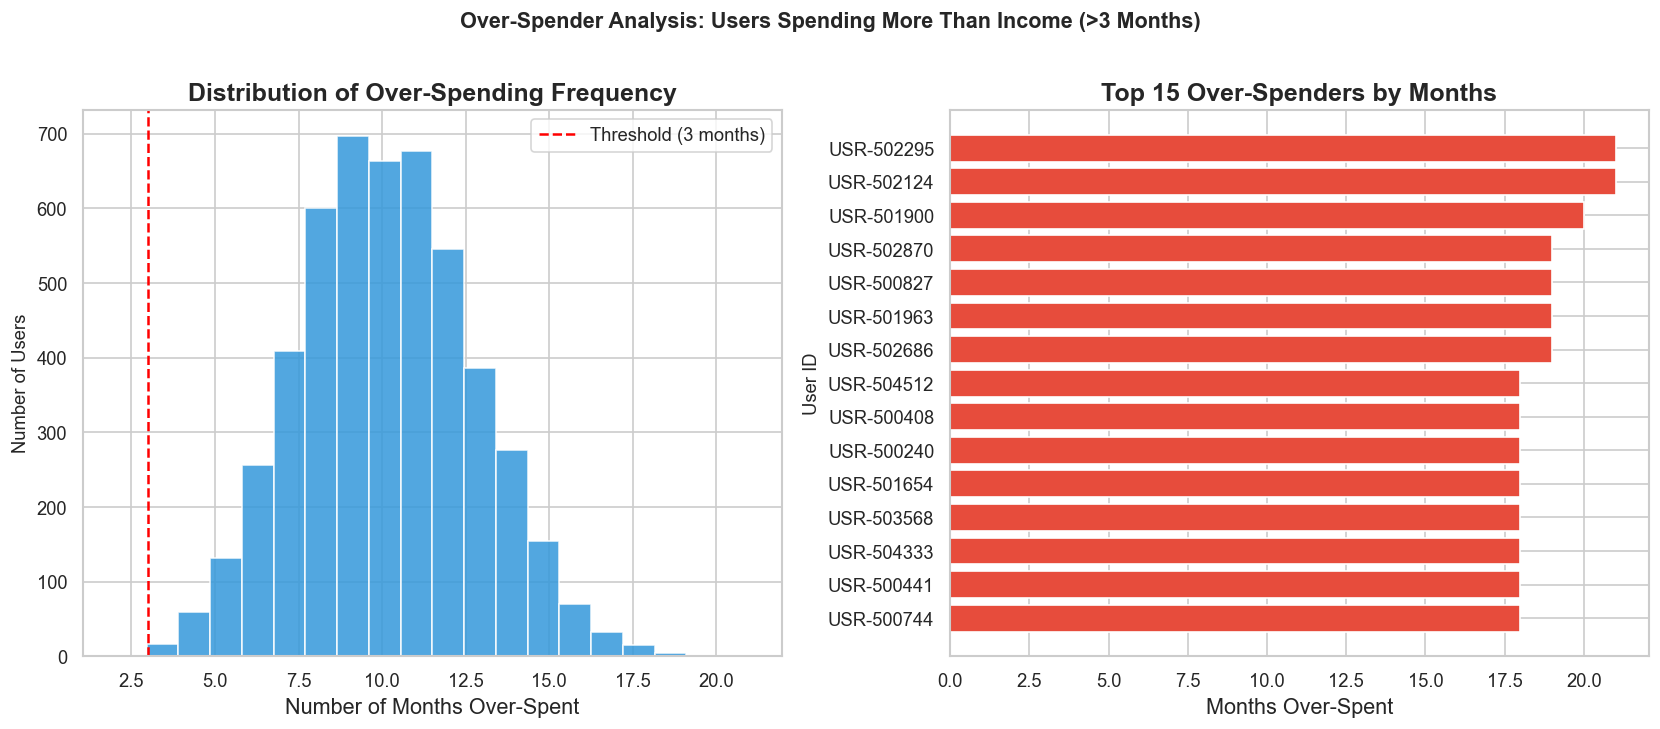

In [13]:
# TASK 10: Flag Over-Spenders (Expenses > Income in > 3 Months)
print()
print("TASK 10: FLAG OVER-SPENDERS")
 
net_savings['is_overspent'] = net_savings['net_savings'] < 0
overspend_count = (
    net_savings.groupby('user_id')['is_overspent']
    .sum().reset_index()
    .rename(columns={'is_overspent': 'overspent_months'})
)
over_spenders = (overspend_count[overspend_count['overspent_months'] > 3]
                 .sort_values('overspent_months', ascending=False))
 
print(f"Total users analysed:        {overspend_count['user_id'].nunique():,}")
print(f"Over-spenders (>3 months):   {len(over_spenders):,}  "
      f"({len(over_spenders)/overspend_count['user_id'].nunique()*100:.1f}%)")
print()
print("Top 10 worst over-spenders:")
print(over_spenders.head(10).to_string(index=False))
 
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
 
# Left: histogram
axes[0].hist(overspend_count['overspent_months'], bins=20,
             color='#3498db', edgecolor='white', alpha=0.85)
axes[0].axvline(3, color='red', linestyle='--', linewidth=1.5,
                label='Threshold (3 months)')
axes[0].set_xlabel('Number of Months Over-Spent', fontsize=13)
axes[0].set_ylabel('Number of Users', fontsize=11)
axes[0].set_title('Distribution of Over-Spending Frequency',
                  fontsize=15, fontweight='bold')
axes[0].legend()
 
# Right: top 15 bar chart
top15 = over_spenders.head(15)
axes[1].barh(top15['user_id'], top15['overspent_months'],
             color='#e74c3c', edgecolor='white')
axes[1].set_xlabel('Months Over-Spent', fontsize=13)
axes[1].set_ylabel('User ID', fontsize=11)
axes[1].set_title('Top 15 Over-Spenders by Months',
                  fontsize=15, fontweight='bold')
axes[1].invert_yaxis()
 
plt.suptitle('Over-Spender Analysis: Users Spending More Than Income (>3 Months)',
             fontsize=13, fontweight='bold', y=1.01)
plt.tight_layout()
plt.savefig('chart8_overspenders.png', bbox_inches='tight')
plt.show()

In [14]:
# TASK 11: Summary — 5 Key Insights for the FinTrack Product Team
print()
print("TASK 11: 5 KEY INSIGHTS FOR FINTRACK PRODUCT TEAM")
 
total_income = income_df['amount_ngn'].sum()
total_expense = expense_df['amount_ngn'].sum()
net_total = total_income - total_expense
overall_savings_rate = (net_total / total_income) * 100 if total_income > 0 else 0
top_expense_cat = expense_df.groupby('category')['amount_ngn'].sum().idxmax()
top_bank = df.groupby('bank')['transaction_id'].count().idxmax()
pct_overspenders = (len(over_spenders) /
                    overspend_count['user_id'].nunique() * 100)
 
print(f"  Total Income:       ₦{total_income:>15,.0f}")
print(f"  Total Expenses:     ₦{total_expense:>15,.0f}")
print(f"  Net Savings:        ₦{net_total:>15,.0f}")
print(f"  Overall Svgs Rate:  {overall_savings_rate:>14.1f}%")
print()
print("-" * 60)
print("INSIGHT 1 — Expenses Dwarf Income Records")
print("  Expense records (63,551) outnumber income records (11,449)")
print("  by 5.5x. FinTrack should prompt users to log all income")
print("  sources during onboarding for accurate budget tracking.")
print()
print("INSIGHT 2 — Over-Spending is Widespread")
print(f"  {pct_overspenders:.1f}% of users spent more than their income in")
print("  more than 3 months. This group is the primary target for")
print("  real-time budget alerts and spending limit features.")
print()
print(f"INSIGHT 3 — {top_expense_cat} is the Top Spending Category")
print("  This category leads total expenditure across all users.")
print("  FinTrack should provide category-specific budget caps")
print("  and weekly spending summaries for this segment.")
print()
print(f"INSIGHT 4 — {top_bank} Dominates Transaction Volume")
print("  The most-used bank/fintech handles the most transactions.")
print("  Prioritising API integration here will maximise data")
print("  coverage and user adoption.")
print()
print("INSIGHT 5 — Seasonal Spending Peaks Are Identifiable")
print("  The heatmap reveals specific months where categories")
print("  like Food, Rent, and Entertainment spike. FinTrack can")
print("  send proactive budget alerts before high-spend periods.")
print()
print("=" * 60)
print("All 8 charts saved as PNG files in the working directory.")
print("=" * 60)
 


TASK 11: 5 KEY INSIGHTS FOR FINTRACK PRODUCT TEAM
  Total Income:       ₦  4,399,924,700
  Total Expenses:     ₦  3,660,710,070
  Net Savings:        ₦    739,214,630
  Overall Svgs Rate:            16.8%

------------------------------------------------------------
INSIGHT 1 — Expenses Dwarf Income Records
  Expense records (63,551) outnumber income records (11,449)
  by 5.5x. FinTrack should prompt users to log all income
  sources during onboarding for accurate budget tracking.

INSIGHT 2 — Over-Spending is Widespread
  99.6% of users spent more than their income in
  more than 3 months. This group is the primary target for
  real-time budget alerts and spending limit features.

INSIGHT 3 — Savings is the Top Spending Category
  This category leads total expenditure across all users.
  FinTrack should provide category-specific budget caps
  and weekly spending summaries for this segment.

INSIGHT 4 — GTBank Dominates Transaction Volume
  The most-used bank/fintech handles the most 